In [8]:
import pandas as pd
import numpy as np

from sklearn.model_selection import train_test_split
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import GradientBoostingClassifier
from sklearn.metrics import accuracy_score, f1_score

from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt
import seaborn as sns

import warnings
warnings.filterwarnings("ignore")

In [9]:
df = pd.read_csv("D:\EDA projects\Loan_prediction_model\data\Loan.csv")

print(df.shape)
df.head()

(367, 13)


,Loan_ID,Gender,Married,Dependents,Education,Self_Employed,ApplicantIncome,CoapplicantIncome,LoanAmount,Loan_Amount_Term,Credit_History,Property_Area,Loan_Status
0,LP001015,Male,Yes,0,Graduate,No,5720,0,110.0,360.0,1.0,Urban,Y
1,LP001022,Male,Yes,1,Graduate,No,3076,1500,126.0,360.0,1.0,Urban,Y
2,LP001031,Male,Yes,2,Graduate,No,5000,1800,208.0,360.0,1.0,Urban,Y
3,LP001035,Male,Yes,2,Graduate,No,2340,2546,100.0,360.0,NaN,Urban,N
4,LP001051,Male,No,0,Not Graduate,No,3276,0,78.0,360.0,1.0,Urban,Y


# Selecting features and target

In [10]:
X = df.drop(columns=["Loan_Status", "Loan_ID"], errors="ignore")
y = df["Loan_Status"]

print("Features:", X.shape)
print("Target:", y.shape)

print(y.value_counts())

Features: (367, 11)
Target: (367,)
Loan_Status
Y    283
N     84
Name: count, dtype: int64


# Identify numerical and categorical columns

In [11]:
numerical_columns = X.select_dtypes(
    include=["int64", "float64"]
).columns.tolist()

categorical_columns = X.select_dtypes(
    include=["object"]
).columns.tolist()

print("Numerical columns:", numerical_columns)
print("Categorical columns:", categorical_columns)

Numerical columns: ['ApplicantIncome', 'CoapplicantIncome', 'LoanAmount', 'Loan_Amount_Term', 'Credit_History']
Categorical columns: ['Gender', 'Married', 'Dependents', 'Education', 'Self_Employed', 'Property_Area']


# Train-Test split

In [12]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Training rows:", X_train.shape[0])
print("Testing rows:", X_test.shape[0])

Training rows: 293
Testing rows: 74


# Handle missing values and encode categories

In [13]:
numerical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

categorical_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="most_frequent")),
    ("encoder", OneHotEncoder(handle_unknown="ignore"))
])

preprocessor = ColumnTransformer([
    ("num", numerical_pipeline, numerical_columns),
    ("cat", categorical_pipeline, categorical_columns)
])

# Create all models

In [15]:
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),

    "Decision Tree": DecisionTreeClassifier(
        random_state=42
    ),

    "Random Forest": RandomForestClassifier(
        n_estimators=100,
        random_state=42
    ),

    "SVM": SVC(),

    "KNN": KNeighborsClassifier(
        n_neighbors=5
    ),

    "Gradient Boosting": GradientBoostingClassifier(
        random_state=42
    )
}

# Train and evaluate every model

In [16]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

results = []

trained_models = {}

for name, algorithm in models.items():

    model = Pipeline([
        ("preprocessor", preprocessor),
        ("classifier", algorithm)
    ])

    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)

    results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision": precision_score(
            y_test, y_pred, pos_label="Y", zero_division=0
        ),
        "Recall": recall_score(
            y_test, y_pred, pos_label="Y", zero_division=0
        ),
        "F1 Score": f1_score(
            y_test, y_pred, pos_label="Y", zero_division=0
        )
    })

    trained_models[name] = model

print("All models trained successfully!")

All models trained successfully!


## Compare results

In [17]:
results_df = pd.DataFrame(results)

results_df = results_df.sort_values(
    by="F1 Score",
    ascending=False
)

results_df.round(3)

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.946,0.934,1.000,0.966
3,SVM,0.932,0.919,1.000,0.958
4,KNN,0.932,0.933,0.982,0.957
2,Random Forest,0.932,0.933,0.982,0.957
5,Gradient Boosting,0.932,0.933,0.982,0.957
1,Decision Tree,0.851,0.911,0.895,0.903


# Visualize model performance

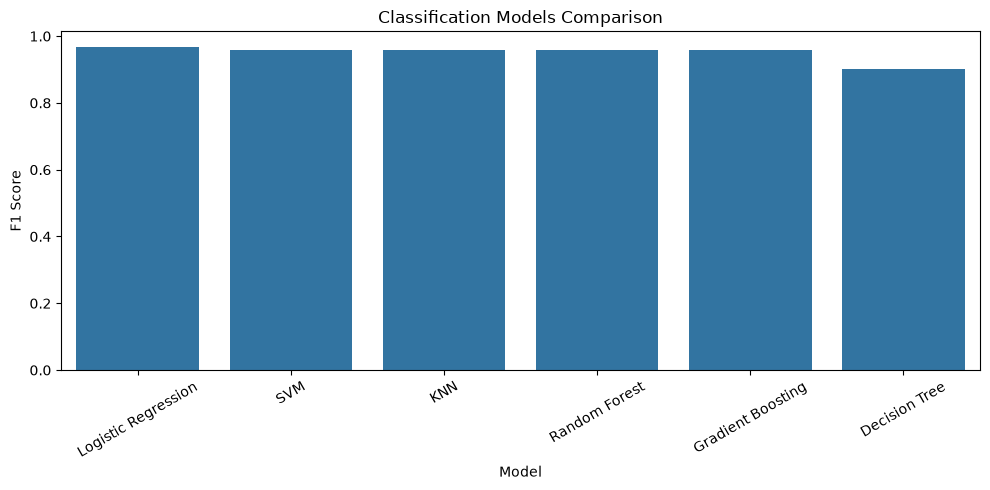

In [18]:
plt.figure(figsize=(10, 5))

sns.barplot(
    data=results_df,
    x="Model",
    y="F1 Score"
)

plt.title("Classification Models Comparison")
plt.xlabel("Model")
plt.ylabel("F1 Score")

plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

## Compare confusion matrices

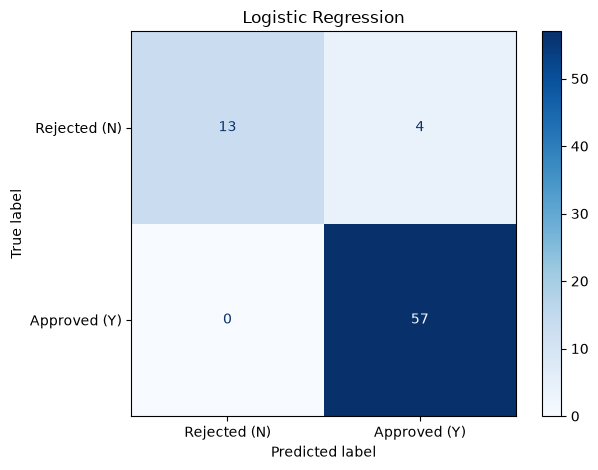

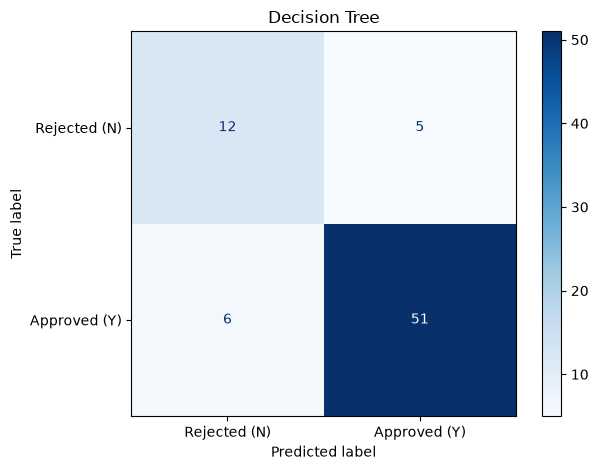

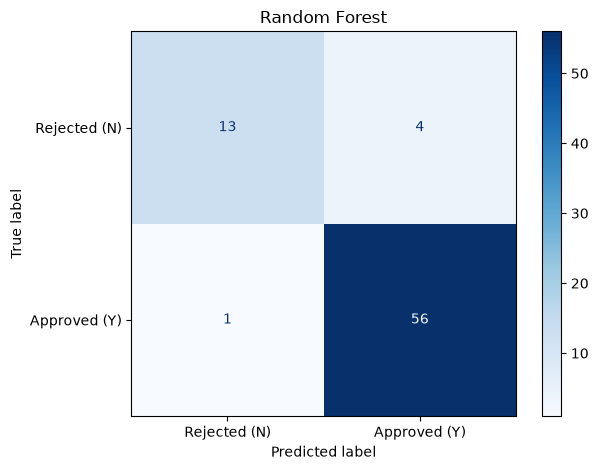

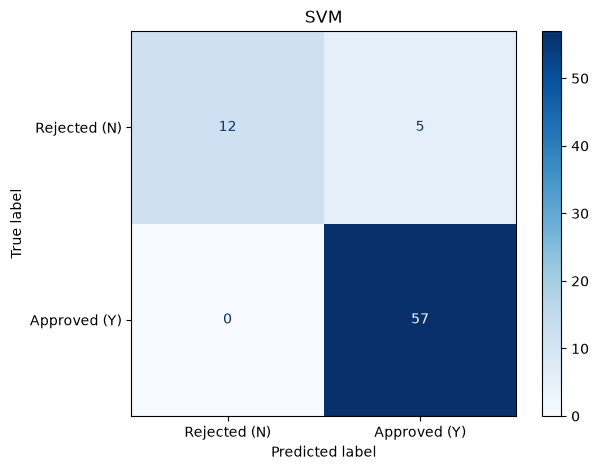

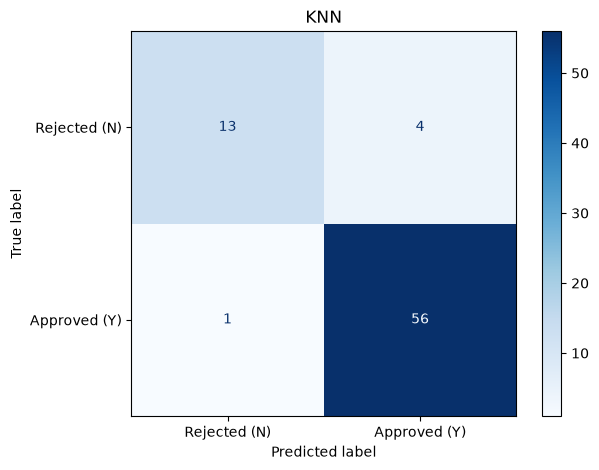

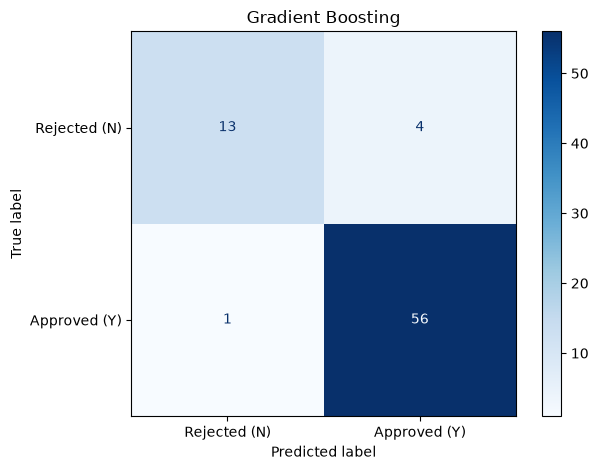

In [19]:
from sklearn.metrics import ConfusionMatrixDisplay
import matplotlib.pyplot as plt

for name, model in trained_models.items():

    y_pred = model.predict(X_test)

    ConfusionMatrixDisplay.from_predictions(
        y_test,
        y_pred,
        labels=["N", "Y"],
        display_labels=["Rejected (N)", "Approved (Y)"],
        cmap="Blues"
    )

    plt.title(name)
    plt.tight_layout()
    plt.show()

# Save the best model

In [20]:
best_model_name = results_df.iloc[0]["Model"]

best_model = trained_models[best_model_name]

print("Best model:", best_model_name)
print(
    "F1 Score:",
    round(results_df.iloc[0]["F1 Score"], 3)
)

Best model: Logistic Regression
F1 Score: 0.966


# Save the trained model

In [21]:
import joblib
import os

os.makedirs("../models", exist_ok=True)

joblib.dump(
    best_model,
    "D:\\EDA projects\\Loan_prediction_model\\models\\loan_model.pkl"
)

print("Best model saved successfully!")

Best model saved successfully!
